In [1]:
# PCA for Dimensionality Reduction - Wine Dataset

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
# 1. Load dataset
df = pd.read_csv("Wine.csv")

In [3]:
# Display first 5 rows
print("Original Dataset:")
print(df.head())

Original Dataset:
   Alcohol  Malic_Acid   Ash  Ash_Alcanity  Magnesium  Total_Phenols  \
0    14.23        1.71  2.43          15.6        127           2.80   
1    13.20        1.78  2.14          11.2        100           2.65   
2    13.16        2.36  2.67          18.6        101           2.80   
3    14.37        1.95  2.50          16.8        113           3.85   
4    13.24        2.59  2.87          21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280  Proline  Customer_Segment  
0   3.92     1065                 1 

In [4]:
# 2. Separate features and target
X = df.iloc[:, 0:13].values
y = df.iloc[:, 13].values


In [5]:
# 3. Standardize the features
sc = StandardScaler()
X_scaled = sc.fit_transform(X)

In [6]:
# 4. Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [7]:
# 5. Create DataFrame of reduced data
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)

print("\nReduced Dataset:")
print(pca_df.head())


Reduced Dataset:
   Principal Component 1  Principal Component 2
0               3.316751               1.443463
1               2.209465              -0.333393
2               2.516740               1.031151
3               3.757066               2.756372
4               1.008908               0.869831


In [8]:
# 6. Explained variance
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Retained:")
print(sum(pca.explained_variance_ratio_))


Explained Variance Ratio:
[0.36198848 0.1920749 ]

Total Variance Retained:
0.5540633835693527


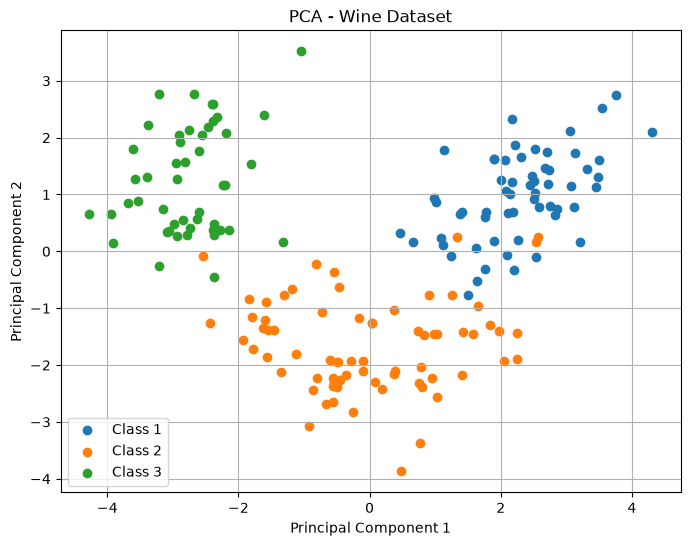

In [9]:
# 7. Visualization
plt.figure(figsize=(8, 6))

for label in sorted(set(y)):
    plt.scatter(
        X_pca[y == label, 0],
        X_pca[y == label, 1],
        label=f"Class {label}"
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Wine Dataset")
plt.legend()
plt.grid()
plt.show()